In [2]:
import os
import random
import math
import time
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
%matplotlib inline

import gdown

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import LocalOutlierFactor
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    precision_recall_fscore_support,
    roc_auc_score, roc_curve
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

In [3]:
# 재현성 확보를 위한 랜덤 시드 고정
def set_seed(seed=42):
    # 모든 난수 생성기의 시드를 고정하여 재현성을 보장한다
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # 일부 cuDNN 연산의 비결정성도 제거
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

SEED = 42
set_seed(SEED)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'사용 디바이스: {device}')


사용 디바이스: cuda


## 데이터 준비

In [4]:
# 데이터 다운로드
DATA_DIR = './data/SWaT'
os.makedirs(DATA_DIR, exist_ok=True)

train_file = os.path.join(DATA_DIR, 'normal.csv')
test_file = os.path.join(DATA_DIR, 'attack.csv')

if not os.path.exists(train_file):
    gdown.download(id="1IlhyYBIL53qH9cHOPtAYafQDqc_LDelc",
                   output=train_file,
                   quiet=False)

if not os.path.exists(test_file):
    gdown.download(id="1r2Clpg1fdSuJHemy0OyPs_7zwDLHPb3A",
                   output=test_file,
                   quiet=False)

Downloading...
From (original): https://drive.google.com/uc?id=1IlhyYBIL53qH9cHOPtAYafQDqc_LDelc
From (redirected): https://drive.google.com/uc?id=1IlhyYBIL53qH9cHOPtAYafQDqc_LDelc&confirm=t&uuid=6f19613d-5277-435a-8b92-3d4cce7c8047
To: /content/data/SWaT/normal.csv
100%|██████████| 402M/402M [00:04<00:00, 85.4MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1r2Clpg1fdSuJHemy0OyPs_7zwDLHPb3A
From (redirected): https://drive.google.com/uc?id=1r2Clpg1fdSuJHemy0OyPs_7zwDLHPb3A&confirm=t&uuid=ebfe34fe-4bcd-478e-addf-d5d13a51bd96
To: /content/data/SWaT/attack.csv
100%|██████████| 427M/427M [00:06<00:00, 68.5MB/s]


In [5]:
# 데이터 로드 및 train/validation/test 분할
"""
- train: 정상 데이터 중 앞부분 80% - "정상 패턴"을 학습
- validation: 정상 데이터 중 뒷부분 20% - 학습이 잘 되었는지 확인
- test: 공격이 포함된 별도 파일 - 실제로 이상치를 잘 찾는지 평가
"""

# ==== 정상 데이터 로드 ====
df_normal = pd.read_csv(train_file)
df_normal = df_normal.dropna(axis=0)
print(f'정상 데이터 컬럼: {df_normal.columns.tolist()[:5]}...(총 {len(df_normal.columns)}개)')
print(f'정상 데이터 크기: {df_normal.shape}')

# 'Timestamp', 'Normal/Attack' 컬럼 제거
df_normal.columns = [c.strip() for c in df_normal.columns]
df_normal = df_normal.drop(['Timestamp', 'Normal/Attack'], axis=1)

# 80/20 시간순 분할
split_idx = int(len(df_normal)*0.8)
trainset = df_normal.iloc[:split_idx].to_numpy(dtype=np.float32)
validset = df_normal.iloc[split_idx:].to_numpy(dtype=np.float32)

# ==== 공격 데이터 로드 ====
df_attack = pd.read_csv(test_file)
df_attack = df_attack.dropna(axis=0)

test_label = df_attack['Normal/Attack'].copy()
test_label = (test_label != 'Normal').astype(np.int32).to_numpy()

# 센서 데이터만 남김
df_attack.columns = [c.strip() for c in df_attack.columns]
columns = [c for c in df_attack.columns if c not in ['Timestamp', 'Normal/Attack']]
testset = df_attack[columns].to_numpy(dtype=np.float32)

# ==== 요약 출력 ====
print(f'Train set: {trainset.shape}')
print(f'Validation set: {validset.shape}')
print(f'Test set: {testset.shape}')
print(f'Test label 공격 비율: {test_label.mean()*100:.2f}%')
print(f'센서 변수 개수: {trainset.shape[1]}개')

정상 데이터 컬럼: [' Timestamp', 'FIT101', 'LIT101', ' MV101', 'P101']...(총 53개)
정상 데이터 크기: (395298, 53)
Train set: (316238, 51)
Validation set: (79060, 51)
Test set: (449919, 51)
Test label 공격 비율: 12.14%
센서 변수 개수: 51개


In [6]:
pd.DataFrame(trainset, columns=columns).head()

,FIT101,LIT101,MV101,P101,P102,AIT201,AIT202,AIT203,FIT201,MV201,...,FIT504,P501,P502,PIT501,PIT502,PIT503,FIT601,P601,P602,P603
0,2.427057,522.846680,2.0,2.0,1.0,262.016113,8.396437,328.633698,2.445391,2.0,...,0.307786,2.0,1.0,250.865204,1.649953,189.598801,0.000128,1.0,1.0,1.0
1,2.446274,522.885986,2.0,2.0,1.0,262.016113,8.396437,328.633698,2.445391,2.0,...,0.307786,2.0,1.0,250.865204,1.649953,189.678894,0.000128,1.0,1.0,1.0
2,2.489191,522.846680,2.0,2.0,1.0,262.016113,8.394514,328.633698,2.442316,2.0,...,0.308619,2.0,1.0,250.881195,1.649953,189.678894,0.000128,1.0,1.0,1.0
3,2.534350,522.964478,2.0,2.0,1.0,262.016113,8.394514,328.633698,2.442316,2.0,...,0.308619,2.0,1.0,250.881195,1.649953,189.614807,0.000128,1.0,1.0,1.0
4,2.569260,523.474792,2.0,2.0,1.0,262.016113,8.394514,328.633698,2.443085,2.0,...,0.308619,2.0,1.0,250.881195,1.649953,189.502701,0.000128,1.0,1.0,1.0


In [7]:
# 정규화(StandardScaler)
scaler = StandardScaler()

trainset = scaler.fit_transform(trainset)

# data leakage 방지를 위해서 validset, testset은 fit하지 않고 transform만 한다
validset = scaler.transform(validset)
testset = scaler.transform(testset)

# 정규화 후 평균, 표준편차 확인
print(f'Train 평균: {trainset.mean():.4f}, 표준편차: {trainset.std():.4f}')
print(f'Test 평균: {testset.mean():.4f}, 표준편차: {testset.std():.4f}')

Train 평균: 0.0000, 표준편차: 0.9075
Test 평균: -0.8242, 표준편차: 7.3403


## 점 기반 이상치 탐지(LOF & Isolation Forest)
### 점 기반 접근이란?
각 시점(t)을 n차원 벡터로 보고, **시간 순서를 무시한 채** "이 점이 정상 점들과 얼마나 떨어져 있는가"만 평가하는 방식  
장점: 모델이 단순하고 빠름  
한계: 시간적 변화 패턴은 못 잡음
<br>
<br>
### Local Outlier Factor(LOF)
**핵심 아이디어**: 각 점의 "**지역 밀도(local density)**"를 주변 이웃 점들의 밀도와 비교한다.  


*   어떤 점의 주변 밀도가 이웃들에 비해 **상대적으로 훨씬 낮으면** 이상치 후보
*   즉, "주변은 다 빽빽한데 나만 외로운 점"을 찾는 알고리즘  

**주요 하이퍼파라미터**  
* **n_neighbors**: 밀도 비교에 사용할 이웃 수(보통 20~50)
* **novelty=True**: 학습 데이터에 없는 새로운 점을 평가할 때 켬



In [7]:
# LOF 학
print('LOF 학습 중...')
t0 = time.time()

lof = LocalOutlierFactor(
    n_neighbors=20,  # 이웃 20개의 밀도와 비교
    novelty=True,  # 새로운 데이터(test)도 predict/score_samples 사용 가능
    n_jobs=1
)
lof.fit(trainset)

print(f'학습 완료. 소요시간: {time.time() - t0:.1f}초')

LOF 학습 중...
학습 완료. 소요시간: 602.8초


In [8]:
# LOF 이상 점수 계산
print('테스트 데이터에 대한 LOF 점수 계산 중...')
t0 = time.time()
lof_scores = -lof.score_samples(testset)
print(f'완료. 소요시간: {time.time() - t0:.1f}초')
print(f'LOF 점수 통계 - min: {lof_scores.min():.3f}, max: {lof_scores.max():.3f}, mean: {lof_scores.mean():.3f}')

테스트 데이터에 대한 LOF 점수 계산 중...
완료. 소요시간: 819.3초
LOF 점수 통계 - min: 0.903, max: 183.495, mean: 3.508


### Isolation Forest  
**핵심 아이디어**: 데이터를 무작위로 자르는 트리를 많이 만들었을 때, **이상치는 적은 횟수의 분할(짧은 경로)만에 다른 점들로부터 격리**(isolation) 된다.  
* 정상 점은 다른 점들과 비슷하므로 격리하려면 많은 분할이 필요  
* 이상치는 떨어져 있으므로 몇 번만 잘라도 혼자 남음
* 평균 깊이가 짧을수록 이상치 점수가 높음  

**주요 하이퍼파라미터**  
* **n_estimators**: 만들 트리 개수(보통 100~200)
* **contamination**: "학습 데이터에서 몇 %를 이상으로 분류할지"의 비율로, 신뢰할만한 사전지식이 있다면 그 값을 넣고 모르겠으면 'auto' 사용

In [9]:
# Isolation forest 학습
print('Isolation Forest 학습 중...')
t0 = time.time()

iforest = IsolationForest(
    n_estimators=100,  # 트리 100개로 앙상블
    contamination=0.05,  # 학습 데이터에 약 5% 이상치가 있다고 가정
    random_state=SEED,
    n_jobs=1
)
iforest.fit(trainset)
print(f'학습 완료. 소요시간: {time.time() - t0:.1f}초')

# 이상점수 계산
iforest_scores = -iforest.score_samples(testset)
print(f'IF 점수 통계 - min: {iforest_scores.min():.3f}, max: {iforest_scores.max():.3f}, mean: {iforest_scores.mean():.3f}')

Isolation Forest 학습 중...
학습 완료. 소요시간: 1.2초
IF 점수 통계 - min: 0.370, max: 0.717, mean: 0.479


In [55]:
# 평가 함수
def evaluate(scores, labels, threshold, model_name):
    pred = (scores >= threshold).astype(int)
    prec, rec, f1, _ = precision_recall_fscore_support(labels, pred, average='binary', zero_division=0)
    auc = roc_auc_score(labels, scores)

    if model_name:
        print(model_name)
        print(f'threshold: {threshold}')
        print(f'Precison: {prec:.4f}, Recall: {rec:.4f}, F1: {f1:.4f}, AUC: {auc:.4f}')
    return {
        'model': model_name,
        'precision': prec,
        'recall': rec,
        'f1': f1,
        'auc': auc,
        'threshold': threshold
    }

임계값을 어떻게 정할까?  
가장 단순하고 합리적인 방법은 "학습 데이터 점수의 99 percentile"을 임계값으로 사용하는 것. 정상 데이터의 점수 분포에서 상위 1% 위치를 끊는다는 의미

In [11]:
lof_train_scores = -lof.score_samples(trainset)
iforest_train_scores = -iforest.score_samples(trainset)

lof_threshold = np.percentile(lof_train_scores, 99)
iforest_threshold = np.percentile(iforest_train_scores, 99)

# 평가
evaluate(lof_scores, test_label, lof_threshold, 'LOF')
evaluate(iforest_scores, test_label, iforest_threshold, 'Isolation Forest')

LOF
threshold: 1.722471833229065
Precison: 0.3976, Recall: 0.8774, F1: 0.5472, AUC: 0.9253
Isolation Forest
threshold: 0.5949166423977346
Precison: 0.8608, Recall: 0.6195, F1: 0.7205, AUC: 0.8492


{'model': 'Isolation Forest',
 'precision': 0.8608390363039662,
 'recall': 0.6194870104904707,
 'f1': 0.7204880333872754,
 'auc': np.float64(0.849193866488589),
 'threshold': np.float64(0.5949166423977346)}

## DL: LSTM-AE, Transformer-AE  
### AutoEncoder 기반 이상치 탐지 아이디어  
1. **AutoEncoder**를 **"정상 데이터"로만 학습**한다.
2. 학습된 모델은 정상 패턴을 압축 → 복원하는 데 최적화되므로, 정상 입력은 잘 복원하지만 **이상 입력은 복원이 잘 안 된다**.
3. 따라서 **재구성 오차(MSE)**가 곧 **이상 점수**가 된다.  

## Sliding Window  
시계열 전체를 한 번에 처리할 수는 없으므로, window 길이 T의 연속 구간을 만들어 모델 입력으로 사용한다.  
* 학습 시: 윈도우를 stride로 겹쳐 가며 추출 → 데이터 양 증가
* 평가 시: 겹치지 않게(stride=T) 추출하여 모든 시점이 정확히 한 번 평가되도록 함

In [27]:
# Sliding window dataset(Custom Dataset)
class BuildDataset(Dataset):
    def __init__(self,
                 data,
                 timestamps,
                 window_size,
                 slide_size,
                 attacks=None,
                 model_type='reconstruction'):
        self.ts = np.array(timestamps)
        self.tag_values = np.array(data, dtype=np.float32)
        self.window_size = window_size
        self.model_type = model_type

        # ---- 유효한 시작 인덱스 사전 계산 ----
        # reconstruction: data[i:i+W]만 사용 -> i+W <= n
        # prediction: data[i:i+W](입력) + data[i+W](정답) -> i+W < n
        n = len(self.ts)
        last_L_exclusive = (n - window_size + 1) if model_type == 'reconstruction' else (n - window_size)

        self.valid_idxs = []
        for L in range(0, last_L_exclusive, slide_size):
            R = L + window_size - (1 if model_type == 'reconstruction' else 0)
            if self._is_valid_window(L, R):
                self.valid_idxs.append(L)
        print(f'# of valid windows: {len(self.valid_idxs)}')

        # ---- 공격 레이블(test 데이터에만 존재) ----
        if attacks is not None:
            self.attacks = np.array(attacks, dtype=np.float32)
            self.with_attack = True
        else:
            self.with_attack = False

    def _is_valid_window(self, L, R):
        """윈도우 양 끝 인덱스의 타임스탬프 간격이 기대값과 일치하는지 확인"""
        expected_gap = self.window_size - (1 if self.model_type == 'reconstruction' else 0)
        a, b = self.ts[L], self.ts[R]
        if np.issubdtype(self.ts.dtype, np.number):
            return (b-a) == expected_gap

        import dateutil.parser
        from datetime import timedelta
        return (dateutil.parser.parse(str(b)) - dateutil.parser.parse(str(a))) == timedelta(seconds=expected_gap)

    def __len__(self):
        return len(self.valid_idxs)

    def __getitem__(self, idx):
        i = self.valid_idxs[idx]
        last = i + self.window_size

        item = {'given': torch.from_numpy(self.tag_values[i:last])}

        if self.model_type == 'reconstruction':
            item['answer'] = torch.from_numpy(self.tag_values[i:last])
            if self.with_attack:
                item['attack'] = torch.from_numpy(self.attacks[i:last])
        elif self.model_type == 'prediction':
            item['answer'] = torch.from_numpy(self.tag_values[last])
            if self.with_attack:
                item['attack'] = torch.from_numpy(self.attacks[last])
        return item

In [28]:
# ---- 하이퍼파라미터 ----
WINDOW_SIZE = 60
TRAIN_STRIDE = 30
TEST_STRIDE = WINDOW_SIZE
BATCH_SIZE = 128

# ---- 타임스탬프 생성 ----
train_timestamp = np.arange(len(trainset))
valid_timestamp = np.arange(len(validset))
test_timestamp = np.arange(len(testset))

# ---- Dataset 생성 ----
train_ds = BuildDataset(trainset, train_timestamp, WINDOW_SIZE, TRAIN_STRIDE,
                        attacks=None, model_type='reconstruction')
valid_ds = BuildDataset(validset, valid_timestamp, WINDOW_SIZE, TRAIN_STRIDE,
                        attacks=None, model_type='reconstruction')
test_ds = BuildDataset(testset, test_timestamp, WINDOW_SIZE, TEST_STRIDE,
                        attacks=test_label, model_type='reconstruction')

# ---- DataLoader 생성 ----
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
valid_loader = DataLoader(valid_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

# 첫 배치 모양 확인
first_batch = next(iter(train_loader))
print(f"'given' shape: {first_batch['given'].shape}  # (B, T, F)")
print(f"'answer' shape: {first_batch['answer'].shape}  # (B, T, F)")

# of valid windows: 10540
# of valid windows: 2634
# of valid windows: 7498
'given' shape: torch.Size([128, 60, 51])  # (B, T, F)
'answer' shape: torch.Size([128, 60, 51])  # (B, T, F)


### 공통 학습 함수

In [29]:
class EarlyStopping:
    """
    Validation loss가 'patience' epoch 동안 개선되지 않으면 학습을 중단한다.
    그 동안의 best 모델 state_dict를 보관해 두었다가 학습 종료 후 복원할 수 있다.
    """
    def __init__(self, patience=5, min_delta=0.0, verbose=True):
        self.patience = patience
        self.min_delta = min_delta
        self.verbose = verbose
        self.best_loss = float('inf')
        self.counter = 0
        self.early_stop = False
        self.best_state = None
        self.best_epoch = 0

    def __call__(self, valid_loss, model=None, epoch=0):
        if valid_loss < self.best_loss - self.min_delta:
            self.best_loss = valid_loss
            self.best_epoch = epoch
            self.counter = 0
            if model is not None:
                self.best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            self.counter += 1
            if self.verbose:
                print(f'EarlyStopping: 개선 없음({self.counter}/{self.patience})')
            if self.counter >= self.patience:
                self.early_stop = True
        return self.early_stop

    def restore_best(self, model):
        if self.best_state is not None:
            model.load_state_dict(self.best_state)

def adjust_learning_rate(optimizer, epoch, lr_init,
                         schedule='step', step_size=3,
                         gamma=0.5, t_max=10):
    """
    Epoch 기반 학습률 스케쥴러

        - 'step': 매 step_size epoch 마다 gamma배 감소
        - 'exp': 매 epoch 마다 gamma배 감소
        - 'cosine': lr_init*0.5*(1+cos(pi*epoch/t_max))
        - 그 외: lr_init 고정
    """
    if schedule == 'step':
        lr = lr_init * (gamma ** (epoch//step_size))
    elif schedule == 'exp':
        lr = lr_init * (gamma ** epoch)
    elif schedule == 'cosine':
        lr = lr_init * 0.5 * (1 + math.cosine(math.pi * min(epoch, t_max) / t_max))
    else:
        lr = lr_init
    for pg in optimizer.param_groups:
        pg['lr'] = lr
    return lr

def train_epoch(model, loader, optimizer, criterion, device):
    """한 epoch 학습"""
    model.train()
    total_loss = 0.0
    n_batches = 0
    for batch in loader:
        x = batch['given'].to(device)
        y = batch['answer'].to(device)

        optimizer.zero_grad()
        recon = model(x)
        loss = criterion(recon, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        n_batches += 1
    return total_loss / n_batches

@torch.no_grad()
def valid_epoch(model, loader, optimizer, criterion, device):
    # 한 epoch 검증(gradient 계산 X)
    model.eval()
    total_loss = 0
    n_batches = 0
    for batch in loader:
        x = batch['given'].to(device)
        y = batch['answer'].to(device)

        optimizer.zero_grad()
        recon = model(x)
        loss = criterion(recon, y)
        total_loss += loss.item()
        n_batches += 1
    return total_loss / n_batches

def train_model(model, train_loader, valid_loader,
                n_epochs=10, lr=1e-3, device='cpu',
                patience=5, lr_schedule='step',
                lr_step_size=3, lr_gamma=0.5,
                restore_best=True):
    """
    전체 학습 루프 - EarlyStopping + LR scheduler

    매 epoch:
        1) 현재 epoch에 맞는 learning rate를 스케줄러로 조정
        2) train loss, vaild loss 계산
        3) EarlyStopping이 best 모델을 보관하고 patience 초과 시 중단
    학습 종료 후 restore_best=True 이면 best valid loss 시점의 가중치로 복원
    """
    optimizer = torch.optim.Adam(model.parameters(),lr=lr)
    criterion = nn.MSELoss()
    history = {'train_loss': [], 'valid_loss': [], 'lr': []}

    early_stopping = EarlyStopping(patience=patience, verbose=True)

    for epoch in range(1, n_epochs + 1):
        t0 = time.time()
        # epoch 0부터 세는 스케줄러 관례에 맞춰 (epoch-1) 전달
        cur_lr = adjust_learning_rate(optimizer, epoch, lr, schedule=lr_schedule,
                                      step_size=lr_step_size, gamma=lr_gamma,
                                      t_max=n_epochs)

        train_loss = train_epoch(model, train_loader, optimizer, criterion, device)
        valid_loss = valid_epoch(model, valid_loader,optimizer, criterion, device)

        history['train_loss'].append(train_loss)
        history['valid_loss'].append(valid_loss)
        history['lr'].append(cur_lr)

        print(f'Epoch {epoch:2d}/{n_epochs} | lr={cur_lr:.2e} | ',
              f'Train Loss: {train_loss:.6f} | Valid Loss: {valid_loss:.6f} | ',
              f'Time: {time.time() - t0:.1f}s')

        if early_stopping(valid_loss, model, epoch=epoch):
            print(f'==> EarlyStopping: epoch {epoch}에서 학습 조기 종료')
            break

    if restore_best:
        early_stopping.restore_best(model)
        print(f'==> best valid loss = {early_stopping.best_loss:.6f} ',
              f'(epoch {early_stopping.best_epoch}) 시점의 가중치로 복원 완료')

    return history

재구성 오차 → 시점별 이상 점수  
테스트 윈도우의 재구성 오차를 계산하고, 그것을 시점별 점수로 변환한다.  
* 모델은 윈도우 [T, F]를 입력받아 [T, F]로 복원
* 시점별 MSE [T] 형태
* 겹치지 않게 윈도우를 뽑았으므로 윈도우 점수들을 이어 붙이면 원본 시계열 길이의 점수 배열이 됨

In [30]:
@torch.no_grad()
def compute_anomaly_scores(model, loader, device):
    """
    Returns
    --------
    scores: (total_len,) - 시점별 이상 점수
    labels: (total_len,) - 시점별 실제 라벨
    """
    model.eval()
    all_scores, all_labels = [], []

    for batch in loader:
        x = batch['given'].to(device)
        y = batch['answer'].to(device)
        recon = model(x)  # (B, T, F)

        # 시점별 MSE: 변수(F) 차원 평균
        per_step_mse = ((recon - y) ** 2).mean(dim=-1)  # (B, T)

        all_scores.append(per_step_mse.cpu().numpy().flatten())
        all_labels.append(batch['attack'].numpy().flatten())

    scores = np.concatenate(all_scores)
    labels = np.concatenate(all_labels).astype(int)
    return scores, labels

def plot_learning_curves(history, title='Training Curves'):
    """
    history 딕셔너리를 받아 Train/Valid Loss 및 Learning Rate 곡선을 출력합니다.

    :param history: 'train_loss', 'valid_loss', 'lr' 키를 갖는 딕셔너리
    :param title: 그래프 전체 제목
    """
    epochs = range(1, len(history['train_loss']) + 1)

    # 1행 2열 구조의 서브플롯 생성
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle(title, fontsize=14, fontweight='bold')

    # 1. Train vs Valid Loss 곡선
    ax1.plot(epochs, history['train_loss'], label='Train Loss', color='tab:blue', linewidth=2)
    if 'valid_loss' in history and len(history['valid_loss']) > 0:
        ax1.plot(epochs, history['valid_loss'], label='Valid Loss', color='tab:orange', linewidth=2)

    ax1.set_title('Loss Curves')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(True, linestyle='--', alpha=0.6)

    # 2. Learning Rate 곡선
    if 'lr' in history and len(history['lr']) > 0:
        ax2.plot(epochs, history['lr'], label='Learning Rate', color='tab:green', linewidth=2)
        ax2.set_title('Learning Rate Schedule')
        ax2.set_xlabel('Epochs')
        ax2.set_ylabel('Learning Rate')

        # 학습률 변화 폭이 큰 경우 Log Scale 사용 검토
        # ax2.set_yscale('log')
        ax2.legend()
        ax2.grid(True, linestyle='--', alpha=0.6)
    else:
        ax2.axis('off')

    plt.tight_layout()
    plt.show()

## LSTM AutoEncoder

In [16]:
class LSTMAutoEncoder(nn.Module):
    """
    LSTM 기반 Seq-to-Seq AutoEncoder

    Parameters
    -----------
    n_features: 입력 변수 개수 F
    hidden_size: LSTM hidden state 차원
    n_layers: 쌓을 LSTM 층 개수
    dropout: 층 사이 dropout 비율(n_layers >= 2 일 때만 적용됨)
    """
    def __init__(self, n_features, hidden_size=64, n_layers=2, dropout=0.1):
        super().__init__()
        self.n_features = n_features
        self.hidden_size = hidden_size
        self.n_layers = n_layers

        # Encoder: [B, T, F] -> 마지막 hidden state
        self.encoder = nn.LSTM(
            input_size=n_features,
            hidden_size=hidden_size,
            num_layers=n_layers,
            batch_first=True,
            dropout=dropout if n_layers >= 2 else 0.0
        )

        # Decoder: 압축된 벡터를 T번 반복 입력 -> [B, T, hidden_size]
        self.decoder = nn.LSTM(
            input_size=hidden_size,
            hidden_size=hidden_size,
            num_layers=n_layers,
            batch_first=True,
            dropout=dropout if n_layers >= 2 else 0.0
        )

        # hidden 차원 -> 원본 변수 차원 F
        self.output_layer = nn.Linear(hidden_size, n_features)

    def forward(self, x):
        """
        입력: [B, T, F]
        출력: [B, T, F]
        """
        B, T, _ = x.shape

        # ----- Encoding -----
        # _: 시점별 출력은 사용하지 않음
        # (hidden, cell): 마지막 시점의 (hidden, cell) state, shape [n_layers, B, hidden_size]
        _, (hidden, cell) = self.encoder(x)

        # ----- 잠재표현(latent) 생성 -----
        # 가장 윗층의 마지막 hidden을 시퀀스 요약으로 사용
        latent = hidden[-1]  # [B, hidden_size]

        # Decoder의 입력으로 latent를 T번 반복(모든 시점에 같은 요약을 주입)
        dec_input = latent.unsqueeze(1).repeat(1, T, 1)  # [B, T, hidden_size]

        # ----- Decoding -----
        # decoder의 초기 hidden/cell을 encoder의 최종 state로 설정해 정보를 이어준다.
        dec_output, _ = self.decoder(dec_input, (hidden, cell))  # [B, T, hidden_size]

        # ----- 출력 -----
        recon = self.output_layer(dec_output)  # [B, T, F]
        return recon


모델 인스턴스화 및 파라미터 개수 확인

In [17]:
N_FEATURES = trainset.shape[1]
HIDDEN_SIZE = 64
N_LAYERS = 2

lstm_ae = LSTMAutoEncoder(
    n_features=N_FEATURES,
    hidden_size=HIDDEN_SIZE,
    n_layers=N_LAYERS,
    dropout=0.1
).to(device)

# 파라미터 개수
n_params = sum(p.numel() for p in lstm_ae.parameters())
print(f'LSTM-AE 파라미터 수: {n_params:,}')
print(lstm_ae)

LSTM-AE 파라미터 수: 133,107
LSTMAutoEncoder(
  (encoder): LSTM(51, 64, num_layers=2, batch_first=True, dropout=0.1)
  (decoder): LSTM(64, 64, num_layers=2, batch_first=True, dropout=0.1)
  (output_layer): Linear(in_features=64, out_features=51, bias=True)
)


학습

In [18]:
set_seed(SEED)

N_EPOCHS = 30
print('==== LSTM Auto-Encoder 학습 시작 ====')
lstm_history = train_model(
    lstm_ae, train_loader, valid_loader, n_epochs=N_EPOCHS,
    lr=1e-3, device=device, patience=3,
    lr_schedule='step',
    lr_step_size=3,
    lr_gamma=0.5,
    restore_best=True
)

==== LSTM Auto-Encoder 학습 시작 ====
Epoch  1/30 | lr=1.00e-03 |  Train Loss: 0.647516 | Valid Loss: 0.616785 |  Time: 2.2s
Epoch  2/30 | lr=1.00e-03 |  Train Loss: 0.466999 | Valid Loss: 0.536445 |  Time: 0.7s
Epoch  3/30 | lr=5.00e-04 |  Train Loss: 0.422626 | Valid Loss: 0.515616 |  Time: 0.7s
Epoch  4/30 | lr=5.00e-04 |  Train Loss: 0.401862 | Valid Loss: 0.502160 |  Time: 0.7s
Epoch  5/30 | lr=5.00e-04 |  Train Loss: 0.386652 | Valid Loss: 0.490351 |  Time: 0.7s
Epoch  6/30 | lr=2.50e-04 |  Train Loss: 0.375056 | Valid Loss: 0.480884 |  Time: 0.7s
Epoch  7/30 | lr=2.50e-04 |  Train Loss: 0.366296 | Valid Loss: 0.474601 |  Time: 0.7s
Epoch  8/30 | lr=2.50e-04 |  Train Loss: 0.359944 | Valid Loss: 0.471047 |  Time: 0.7s
Epoch  9/30 | lr=1.25e-04 |  Train Loss: 0.354258 | Valid Loss: 0.467440 |  Time: 0.7s
Epoch 10/30 | lr=1.25e-04 |  Train Loss: 0.351037 | Valid Loss: 0.464061 |  Time: 0.7s
Epoch 11/30 | lr=1.25e-04 |  Train Loss: 0.347864 | Valid Loss: 0.462460 |  Time: 0.7s
Epoch 12/

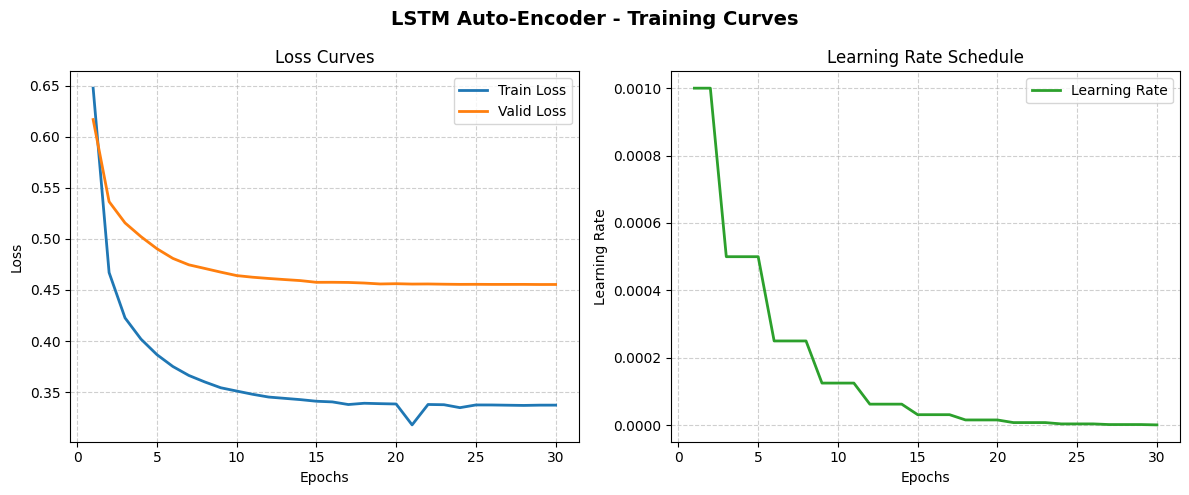

In [19]:
plot_learning_curves(history=lstm_history, title='LSTM Auto-Encoder - Training Curves')

이상 점수 계산 및 평가

In [53]:
# ----- 학습 데이터의 재구성 오차로 임계값 계산 -----
@torch.no_grad()
def compute_train_recon_errors(model, loader, device):
    model.eval()
    errors = []

    for batch in loader:
        x = batch['given'].to(device)
        y = batch['answer'].to(device)
        recon = model(x)
        per_step_mse = ((recon - y) ** 2).mean(dim=-1)  # [B, T]
        errors.append(per_step_mse.cpu().numpy().flatten())
    return np.concatenate(errors)

In [21]:
lstm_train_errors = compute_train_recon_errors(lstm_ae, train_loader, device)
lstm_threshold = np.percentile(lstm_train_errors, 99)
print(f'LSTM-AE 임계값(Train recon error 99%): {lstm_threshold:6f}')

# ----- 테스트 데이터에서 이상 점수 계산 -----
lstm_scores, lstm_labels = compute_anomaly_scores(lstm_ae, test_loader, device)

LSTM-AE 임계값(Train recon error 99%): 1.471972


In [22]:
# ----- 평가 -----
evaluate(lstm_scores, lstm_labels, lstm_threshold, model_name='LSTM-AE')

LSTM-AE
threshold: 1.4719715118408203
Precison: 0.9012, Recall: 0.7181, F1: 0.7993, AUC: 0.9325


{'model': 'LSTM-AE',
 'precision': 0.9012047638754771,
 'recall': 0.7181305192187901,
 'f1': 0.7993188955503895,
 'auc': np.float64(0.9324949521790236),
 'threshold': np.float32(1.4719715)}

## Transformer AutoEncoder

Positional Encoding

In [23]:
class PositionalEncoding(nn.Module):
    """
    Sinusoidal Positional Encoding

    각 위치 pos와 차원 i에 대해:
        PE(pos, 2i) = sin(pos/10000^(2i/d_model))
        PE(pos, 2i+1) = cos(pos/10000^(2i/d_model))

    학습 파라미터가 아니라 buffer로 저장(모델 저장/로드 시 함께 처리됨)
    """
    def __init__(self, d_model, max_len=500):
        super().__init__()

        pe = torch.zeros(max_len, d_model)
        position = torch.arange(max_len, dtype=torch.float).unsqueeze(1)  # (max_len, 1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model)
        )
        pe[:, 0::2] = torch.sin(position * div_term)  # 짝수 차원
        pe[:, 1::2] = torch.cos(position * div_term)  # 홀수 차원
        pe = pe.unsqueeze(0)  # [1, max_len, d_model]

        self.register_buffer('pe', pe)

    def forward(self, x):
        # x: [B, T, d_model] -> 같은 차원의 positional encoding을 더해 반환
        return x + self.pe[:, :x.size(1)]


모델

In [24]:
class TransformerAutoEncoder(nn.Module):
    """
    Parameters
    ----------
    n_features
        입력 변수 개수 F
    d_model
        Transformer hidden 차원
    n_head
        Multi-head attention의 head 수
    n_layers
        Encoder/Decoder 각각의 층 수
    dim_ff
        FeedForward 내부 차원
    dropout
        dropout 비율
    window_size
        입력 시퀀스 길이 T
    """
    def __init__(
            self,
            n_features,
            d_model=64,
            n_head=4,
            n_layers=2,
            dim_ff=128,
            dropout=0.1,
            window_size=60
    ):
        super().__init__()
        self.window_size = window_size
        self.d_model = d_model

        # ----- 입력 임베딩 -----
        self.input_proj = nn.Linear(n_features, d_model)
        self.pos_enc = PositionalEncoding(d_model, max_len=window_size + 10)

        # ----- Encoder -----
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_head,
            dim_feedforward=dim_ff,
            dropout=dropout,
            batch_first=True
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)

        # ---- Decoder -----
        decoder_layer = nn.TransformerDecoderLayer(
            d_model=d_model,
            nhead=n_head,
            dim_feedforward=dim_ff,
            dropout=dropout,
            batch_first=True
        )
        self.decoder = nn.TransformerDecoder(decoder_layer, num_layers=n_layers)

        # ----- 학습 가능한 디코더 쿼리 -----
        # T개의 위치별 query 벡터 -> decoder가 memory를 바라보는 '질문' 역할
        # 입력의 실제 값에 접근하지 않음
        self.dec_query = nn.Parameter(torch.randn(window_size, d_model) * 0.02)

        # ----- 출력 사영 -----
        self.output_proj = nn.Linear(d_model, n_features)

    def forward(self, x):
        """
        x: [B, T, F]
        recon: [B, T, F]
        """
        B, T, _ = x.shape

        # ----- 인코딩 -----
        src = self.input_proj(x)  # [B, T, d_model]
        src=  self.pos_enc(src)  # 위치 정보 주입
        memory = self.encoder(src)  # [B, T, d_model]

        # ----- 디코딩 -----
        tgt = self.dec_query.unsqueeze(0).expand(B, -1, -1)  # [B, T, d_model]
        out = self.decoder(tgt, memory)

        # ----- 출력 사영 -----
        recon = self.output_proj(out)  # [B, T, F]
        return recon

모델 인스턴스화

In [25]:
N_FEATURES = trainset.shape[1]
D_MODEL = 64
N_HEAD = 4
N_LAYERS = 2

transformer_ae = TransformerAutoEncoder(
    n_features=N_FEATURES,
    d_model=D_MODEL,
    n_head=N_HEAD,
    dim_ff=128,
    dropout=0.1,
    window_size=WINDOW_SIZE
).to(device)

n_params = sum(p.numel() for p in transformer_ae.parameters())
print(f'Transformer-AE 파라미터 수: {n_params:,}')
print(transformer_ae)

Transformer-AE 파라미터 수: 177,907
TransformerAutoEncoder(
  (input_proj): Linear(in_features=51, out_features=64, bias=True)
  (pos_enc): PositionalEncoding()
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=128, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (decoder): TransformerDecoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerDecoderLayer(
        (self_attn): MultiheadAttention(
   

학습

In [26]:
set_seed(SEED)

N_EPOCHS = 30
print('==== Transformer AutoEncoder 학습 시작 ====')
transformer_history = train_model(
    transformer_ae, train_loader, valid_loader,
    n_epochs=N_EPOCHS,
    lr=1e-3, device=device, patience=3,
    lr_schedule='step',
    lr_step_size=3,
    lr_gamma=0.5,
    restore_best=True
)

==== Transformer AutoEncoder 학습 시작 ====
Epoch  1/30 | lr=1.00e-03 |  Train Loss: 0.514960 | Valid Loss: 0.461093 |  Time: 1.8s
Epoch  2/30 | lr=1.00e-03 |  Train Loss: 0.361737 | Valid Loss: 0.398878 |  Time: 1.6s
Epoch  3/30 | lr=5.00e-04 |  Train Loss: 0.323697 | Valid Loss: 0.362694 |  Time: 1.6s
Epoch  4/30 | lr=5.00e-04 |  Train Loss: 0.304702 | Valid Loss: 0.344457 |  Time: 1.6s
Epoch  5/30 | lr=5.00e-04 |  Train Loss: 0.289471 | Valid Loss: 0.331534 |  Time: 1.7s
Epoch  6/30 | lr=2.50e-04 |  Train Loss: 0.281055 | Valid Loss: 0.320523 |  Time: 1.6s
Epoch  7/30 | lr=2.50e-04 |  Train Loss: 0.275131 | Valid Loss: 0.314784 |  Time: 1.6s
Epoch  8/30 | lr=2.50e-04 |  Train Loss: 0.270632 | Valid Loss: 0.310772 |  Time: 1.6s
Epoch  9/30 | lr=1.25e-04 |  Train Loss: 0.266872 | Valid Loss: 0.307664 |  Time: 1.6s
Epoch 10/30 | lr=1.25e-04 |  Train Loss: 0.264436 | Valid Loss: 0.305139 |  Time: 1.6s
Epoch 11/30 | lr=1.25e-04 |  Train Loss: 0.262399 | Valid Loss: 0.302539 |  Time: 1.7s
Epo

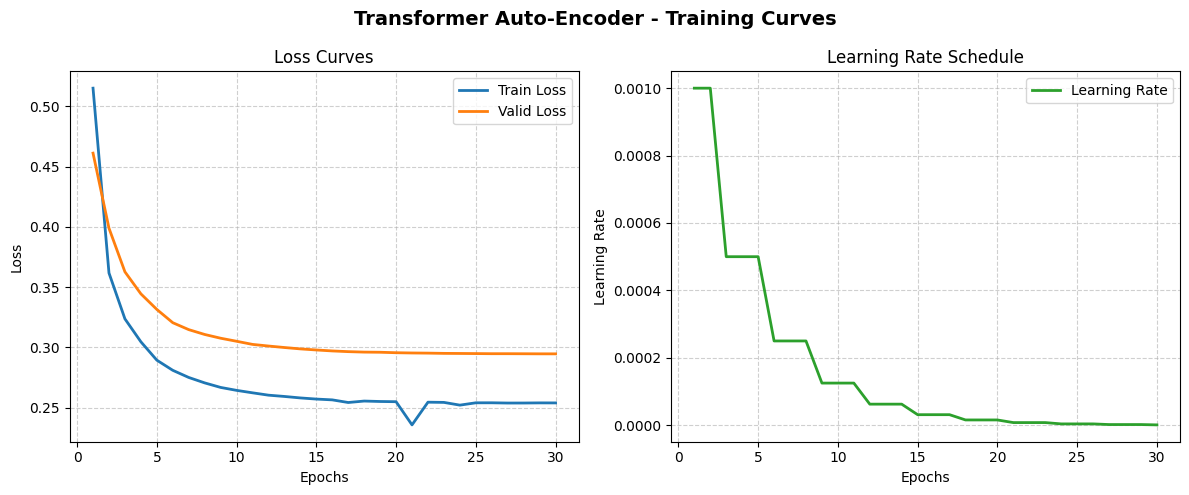

In [27]:
plot_learning_curves(history=transformer_history, title='Transformer Auto-Encoder - Training Curves')

이상 점수 계산 및 평가

In [28]:
trans_train_errors = compute_train_recon_errors(transformer_ae, train_loader, device)
trans_threshold = np.percentile(trans_train_errors, 99)
print(f'Transformer-AE 임계값(Train recon error 99%): {trans_threshold:6f}')

# ----- 테스트 데이터에서 이상 점수 계산 -----
trans_scores, trans_labels = compute_anomaly_scores(transformer_ae, test_loader, device)

# ----- 평가 -----
evaluate(trans_scores, trans_labels, trans_threshold, model_name='Transformer-AE')

Transformer-AE 임계값(Train recon error 99%): 0.709319
Transformer-AE
threshold: 0.7093186378479004
Precison: 0.9013, Recall: 0.7282, F1: 0.8055, AUC: 0.9234


{'model': 'Transformer-AE',
 'precision': 0.9012698412698412,
 'recall': 0.7281887801839434,
 'f1': 0.8055369773616262,
 'auc': np.float64(0.9233565948574489),
 'threshold': np.float32(0.70931864)}

### ModernTCN

모델

In [48]:
class ModernTCNBlock(nn.Module):
    '''
    ModernTCN 기본 단일 블록 (DWConv -> FFN1 -> FFN2 + Residual Connection)
        - x: (B, M, D, N) (배치 수, 변수 수, 임베딩 차원(피처 수), 패치 수)
        - DWConv: Depthwise conv(시간 추 특징 학습)
            - input: (B, M, D, N) -reshape-> (B, M*D, N)
            - output: (B, M*D, N)
        - ConvFFn1: 변수 그룹으로 나눠서 각 변수 내 피처 간 특징 학습
            - Pointwise conv(1x1) + inverted bottleneck
            - input: (B, M*D, N)
            - output: (B, M*D, N)
        - ConvFFn2: 피처 그룹으로 나눠서 각 변수 간 특징 학습
            - Pointwise conv(1x1) + inverted bottleneck
            - input: (B, M*D, N) -reshape-> (B, M, D, N) -permute-> (B, D, M, N) -reshape-> (B, D*M, N)
            - output: (B, D*M, N)
    '''
    def __init__(self, d_model, n_vars, large_kernel_size, ffn_ratio=2, drop=0.1):
        super().__init__()
        expansion_factor = int(d_model * ffn_ratio)
        # 1. DWConv(시간 축 특징 추출)
        self.dw = nn.Conv1d(in_channels=n_vars * d_model,
                            out_channels=n_vars * d_model,
                            kernel_size=large_kernel_size,
                            padding=large_kernel_size // 2,
                            groups=n_vars * d_model)
        self.norm = nn.BatchNorm1d(d_model)

        # 2. ConvFFN1(변수 내부 피처 믹싱)
        self.ffn1pw1 = nn.Conv1d(in_channels=n_vars * d_model,
                                 out_channels=n_vars * expansion_factor,
                                 kernel_size=1,
                                 groups=n_vars)
        self.ffn1pw2 = nn.Conv1d(in_channels=n_vars * expansion_factor,
                                 out_channels=n_vars * d_model,
                                 kernel_size=1,
                                 groups=n_vars)
        self.ffn1act = nn.GELU()
        self.ffn1drop1 = nn.Dropout(drop)
        self.ffn1drop2 = nn.Dropout(drop)

        # 3. FFN2(변수 간 상호작용 믹싱)
        self.ffn2pw1 = nn.Conv1d(in_channels=n_vars * d_model,
                                 out_channels=n_vars * expansion_factor,
                                 kernel_size=1,
                                 groups=d_model)
        self.ffn2pw2 = nn.Conv1d(in_channels=n_vars * expansion_factor,
                                 out_channels=n_vars * d_model,
                                 kernel_size=1,
                                 groups=d_model)
        self.ffn2act = nn.GELU()
        self.ffn2drop1 = nn.Dropout(drop)
        self.ffn2drop2 = nn.Dropout(drop)

    def forward(self, x):
        # (B, M, D, N): (배치 수, 변수 수, 임베딩 차원(피처 수), 패치 수)
        skip = x
        B, M, D, N = x.shape
        x = x.reshape(B, M*D, N)
        x = self.dw(x)
        x = x.reshape(B, M, D, N)
        x = x.reshape(B*M, D, N)
        x = self.norm(x)
        x = x.reshape(B, M, D, N)
        x = x.reshape(B, M * D, N)

        x = self.ffn1drop1(self.ffn1pw1(x))
        x = self.ffn1act(x)
        x = self.ffn1drop2(self.ffn1pw2(x))
        x = x.reshape(B, M, D, N)

        x = x.permute(0, 2, 1, 3)  # (B, D, M, N)
        x = x.reshape(B, D * M, N)
        x = self.ffn2drop1(self.ffn2pw1(x))
        x = self.ffn2act(x)
        x = self.ffn2drop2(self.ffn2pw2(x))
        x = x.reshape(B, D, M, N)
        x = x.permute(0, 2, 1, 3)  # (B, M, D, N)

        x = skip + x
        return x

        # 1. DWConv
        x = x.reshape(B*M, D, P)
        x = x + self.norm1(self.dw_conv(x))

        # 2. ConvFFN1
        x = x + self


class ModernTCN(nn.Module):
    def __init__(self, input_dim, d_model, patch_size, patch_stride, large_kernel_size,
                 num_blocks, ffn_ratio=2, drop=0.1):
        super().__init__()
        self.patch_size = patch_size
        self.patch_stride = patch_stride

        # Patchify & Patch embedding
        self.stem = nn.Sequential(
            nn.Conv1d(1, d_model, kernel_size=patch_size, stride=patch_stride),
            nn.BatchNorm1d(d_model)
        )

        # ModernTCN backbone blocks
        self.blocks = nn.ModuleList([
            ModernTCNBlock(d_model=d_model,
                           n_vars=input_dim,
                           large_kernel_size=large_kernel_size,
                           ffn_ratio=ffn_ratio,
                           drop=drop)
            for _ in range(num_blocks)
        ])

        # Linear projection
        self.proj = nn.Linear(d_model, self.patch_size)


    def forward(self, x):
        # (B, L, M) -> (B, M, 1, L)
        x = x.permute(0, 2, 1)
        x = x.unsqueeze(-2)
        B, M, D, L = x.shape
        x = x.reshape(B*M, D, L)  # (B*M. 1. L)

        # 패딩 처리
        if self.patch_size != self.patch_stride:
            pad_len = self.patch_size - self.patch_stride
            pad = x[:,:,-1:].repeat(1, 1, pad_len)
            x = torch.cat([x, pad], dim=-1)

        # 패치화
        # input: (B*M. 1. L)
        # output: (B*M, D, N)
        x = self.stem(x)
        _, D, N = x.shape

        # 블록에 입력하기 위해 reshape
        # (B*M, D, N) -> (B, M, D, N)
        x = x.reshape(B, M, D, N)

        # Backbone blocks 통과
        for block in self.blocks:
            x = block(x)

        # 마지막 projection: (B, M, D, N) -> (B, M, L)
        # (B, M, D, N) -> (B, M, N, D)
        x = x.permute(0, 1, 3, 2)
        # (B, M, N, patch_size)
        x = self.proj(x)
        # (B, M, N*patch_size)
        x = x.reshape(B, M, -1)
        # (B, M, N*patch_size) -> (B, M, L)
        x = x[:, :, :L]
        # (B, M, L) -> (B, L, M)
        x = x.permute(0, 2, 1)
        return x

모델 인스턴스화

In [49]:
N_FEATURES = trainset.shape[1]
D_MODEL = 64
PATCH_SIZE = 4
PATCH_STRIDE = 2
KERNEL_SIZE = 13
NUM_BLOCKS = 2

moderntcn_ae = ModernTCN(
    input_dim=N_FEATURES,
    d_model=D_MODEL,
    patch_size=PATCH_SIZE,
    patch_stride=PATCH_STRIDE,
    large_kernel_size=KERNEL_SIZE,
    num_blocks=NUM_BLOCKS,
    ffn_ratio=2,
    drop=0.1
).to(device)

n_params = sum(p.numel() for p in moderntcn_ae.parameters())
print(f'ModernTCN-AE 파라미터 수: {n_params:,}')
print(moderntcn_ae)

ModernTCN-AE 파라미터 수: 3,134,404
ModernTCN(
  (stem): Sequential(
    (0): Conv1d(1, 64, kernel_size=(4,), stride=(2,))
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (blocks): ModuleList(
    (0-1): 2 x ModernTCNBlock(
      (dw): Conv1d(3264, 3264, kernel_size=(13,), stride=(1,), padding=(6,), groups=3264)
      (norm): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (ffn1pw1): Conv1d(3264, 6528, kernel_size=(1,), stride=(1,), groups=51)
      (ffn1pw2): Conv1d(6528, 3264, kernel_size=(1,), stride=(1,), groups=51)
      (ffn1act): GELU(approximate='none')
      (ffn1drop1): Dropout(p=0.1, inplace=False)
      (ffn1drop2): Dropout(p=0.1, inplace=False)
      (ffn2pw1): Conv1d(3264, 6528, kernel_size=(1,), stride=(1,), groups=64)
      (ffn2pw2): Conv1d(6528, 3264, kernel_size=(1,), stride=(1,), groups=64)
      (ffn2act): GELU(approximate='none')
      (ffn2drop1): Dropout(p=0.1, inplace=False)
      (

학습

In [50]:
set_seed(SEED)

N_EPOCHS = 30
print('==== ModernTCN AutoEncoder 학습 시작 ====')
moderntcn_history = train_model(
    moderntcn_ae, train_loader, valid_loader,
    n_epochs=N_EPOCHS,
    lr=1e-3, device=device, patience=3,
    lr_schedule='step',
    lr_step_size=3,
    lr_gamma=0.5,
    restore_best=True
)

==== ModernTCN AutoEncoder 학습 시작 ====
Epoch  1/30 | lr=1.00e-03 |  Train Loss: 0.312178 | Valid Loss: 0.505816 |  Time: 41.6s
Epoch  2/30 | lr=1.00e-03 |  Train Loss: 0.196461 | Valid Loss: 0.358910 |  Time: 40.6s
Epoch  3/30 | lr=5.00e-04 |  Train Loss: 0.180404 | Valid Loss: 0.202461 |  Time: 40.8s
Epoch  4/30 | lr=5.00e-04 |  Train Loss: 0.128772 | Valid Loss: 0.199446 |  Time: 40.7s
Epoch  5/30 | lr=5.00e-04 |  Train Loss: 0.119750 | Valid Loss: 0.185271 |  Time: 40.7s
Epoch  6/30 | lr=2.50e-04 |  Train Loss: 0.109781 | Valid Loss: 0.175787 |  Time: 40.7s
Epoch  7/30 | lr=2.50e-04 |  Train Loss: 0.098620 | Valid Loss: 0.183269 |  Time: 40.7s
EarlyStopping: 개선 없음(1/3)
Epoch  8/30 | lr=2.50e-04 |  Train Loss: 0.096166 | Valid Loss: 0.166812 |  Time: 40.7s
Epoch  9/30 | lr=1.25e-04 |  Train Loss: 0.089469 | Valid Loss: 0.171689 |  Time: 40.7s
EarlyStopping: 개선 없음(1/3)
Epoch 10/30 | lr=1.25e-04 |  Train Loss: 0.087227 | Valid Loss: 0.164883 |  Time: 40.7s
Epoch 11/30 | lr=1.25e-04 |  T

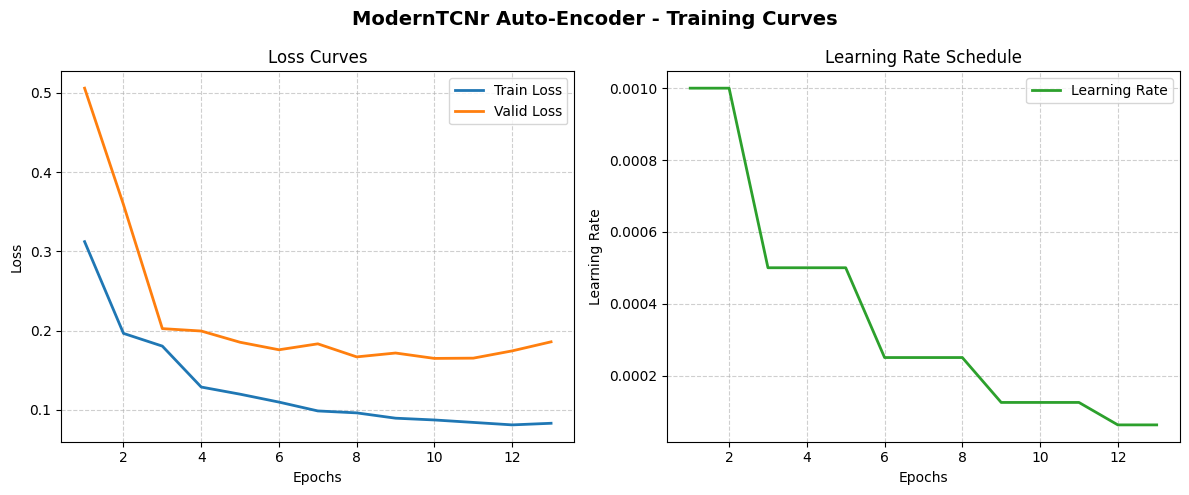

In [51]:
plot_learning_curves(history=moderntcn_history, title='ModernTCNr Auto-Encoder - Training Curves')

이상점수 계산 및 평가

In [56]:
mtcn_train_errors = compute_train_recon_errors(moderntcn_ae, train_loader, device)
mtcn_threshold = np.percentile(mtcn_train_errors, 99)
print(f'ModernTCN-AE 임계값(Train recon error 99%): {mtcn_threshold:6f}')

# ----- 테스트 데이터에서 이상 점수 계산 -----
mtcn_scores, mtcn_labels = compute_anomaly_scores(moderntcn_ae, test_loader, device)

# ----- 평가 -----
evaluate(mtcn_scores, mtcn_labels, mtcn_threshold, model_name='ModernTCN-AE')

ModernTCN-AE 임계값(Train recon error 99%): 0.722046
ModernTCN-AE
threshold: 0.7220458984375
Precison: 0.8982, Recall: 0.7026, F1: 0.7884, AUC: 0.9095


{'model': 'ModernTCN-AE',
 'precision': 0.8981637624133408,
 'recall': 0.7025759407863398,
 'f1': 0.788420814572668,
 'auc': np.float64(0.909494421919032),
 'threshold': np.float32(0.7220459)}